# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

In [3]:
# Hàm phụ: cho tác tử đấu random_player 100 ván khi đi trước (x) và 100 ván khi đi sau (o), đo thời gian mỗi nước
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tictactoe import other
np.random.seed(0)

def danh_gia(agent, ten, N = 100):
    dong = []
    for vai in 'xo':
        t = []
        def dem(board, player = 'x'):
            s = time.perf_counter(); a = agent(board, player); t.append(time.perf_counter() - s); return a
        r = play(dem, random_player, N) if vai == 'x' else play(random_player, dem, N)
        dong.append([ten, 'đi trước' if vai == 'x' else 'đi sau', r[vai], r['d'], r[other(vai)], round(1000 * np.mean(t), 1)])
    return pd.DataFrame(dong, columns = ['Tác tử', 'Vai', 'Thắng', 'Hòa', 'Thua', 'ms/nước'])

def ve(bang, tieu_de):
    nhan = bang['Tác tử'] + ' (' + bang['Vai'] + ')'
    ax = bang[['Thắng', 'Hòa', 'Thua']].set_index(nhan).plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (8, 0.45 * len(bang) + 1.3))
    ax.set_xlabel('số ván'); ax.set_ylabel(''); ax.set_title(tieu_de); ax.invert_yaxis()
    ax.legend(ncol = 3, loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
    plt.show()

In [4]:
# Bốn trạng thái kiểm thử (đến lượt x đi)
def ban(x = (), o = ()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

tests = {'A: x sắp thắng': ban((0, 4), (1, 3)), 'B: x phải đi ô 7': ban((0, 2), (1, 4)),
         'C: bất lợi': ban((2,), (0, 8)), 'D: bàn rỗng': ban()}

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [5]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
1
-1
0


In [6]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [1, -1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, -1, 1, 1, 0, 1, -1, 1, 1, 0, -1, -1, 1, 1, 0, -1, 1, 1, 1, -1, 1, -1, 1, -1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, -1, -1, 0, -1, 1, 1, 1, -1, 0, 1, 1, -1, 1, 1, 1, 0, 0, -1, -1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, 0, 1, -1, 1, -1, 1, 0, 1, -1, 1, 1, 1, 1, 1, -1, 1]
mean utility: 0.34
win probability: 0.6
loss probability: 0.26
draw probability: 0.14


__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [7]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.182,
 1: 0.273,
 2: 0.636,
 3: 0.364,
 4: 0.636,
 5: 0.273,
 6: 0.545,
 7: 0.182,
 8: 0.455}

2
CPU times: total: 78.1 ms
Wall time: 61.5 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.386,
 1: 0.209,
 2: 0.400,
 3: 0.182,
 4: 0.503,
 5: 0.212,
 6: 0.342,
 7: 0.217,
 8: 0.326}

4
CPU times: total: 3.28 s
Wall time: 3.3 s


Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


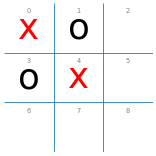


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.800, 5: 0.450, 6: 0.900, 7: 0.750, 8: 1.000}

8

CPU times: total: 31.2 ms
Wall time: 33.3 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### o is about to win

Board:


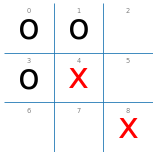


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.120, 5: -0.680, 6: -0.360, 7: -0.760}

2

CPU times: total: 15.6 ms
Wall time: 22.9 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: -0.016, 5: -0.608, 6: -0.016, 7: -0.696}

2

CPU times: total: 141 ms
Wall time: 153 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


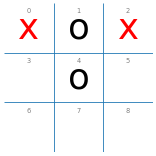


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: -0.200, 5: 0.000, 6: -0.450, 7: 0.350, 8: -0.350}

7

CPU times: total: 15.6 ms
Wall time: 34.5 ms


In [10]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


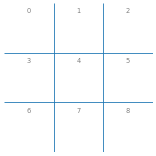


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.409,
 1: 0.166,
 2: 0.335,
 3: 0.164,
 4: 0.551,
 5: 0.256,
 6: 0.261,
 7: 0.258,
 8: 0.286}

4

CPU times: total: 3.55 s
Wall time: 3.8 s


In [11]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


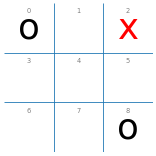


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.750, 3: -0.438, 4: 0.375, 5: -0.750, 6: -0.250, 7: -0.688}

4

CPU times: total: 62.5 ms
Wall time: 79 ms


In [12]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [13]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: -1.000,
 1: 1.000,
 2: -1.000,
 3: 1.000,
 4: 0.000,
 5: -1.000,
 6: 1.000,
 7: -1.000,
 8: 1.000}

Actions: [0, 2, 3, 4, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000, 2: 1.000, 3: 1.000, 4: 1.000, 6: 0.000, 7: 1.000, 8: -1.000}

Actions: [2, 4, 6, 7, 8] (10 total playouts = 2 playouts per action)


{2: 1.000, 4: 1.000, 6: 1.000, 7: -1.000, 8: 1.000}

{'x': 1, 'o': 0, 'd': 0}

In [14]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 95, 'o': 2, 'd': 3}

CPU times: total: 2.53 s
Wall time: 2.87 s

random vs. PMCS (10)


{'x': 23, 'o': 69, 'd': 8}

CPU times: total: 1.53 s
Wall time: 1.62 s


In [15]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 97, 'o': 1, 'd': 2}

CPU times: total: 13.2 s
Wall time: 14.1 s

random vs. PMCS (100)


{'x': 9, 'o': 79, 'd': 12}

CPU times: total: 8.31 s
Wall time: 8.67 s


In [16]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 90, 'o': 3, 'd': 7}

CPU times: total: 8.38 s
Wall time: 8.78 s

PMCS (10) vs. PMCS (100)


{'x': 40, 'o': 42, 'd': 18}

CPU times: total: 5.05 s
Wall time: 5.23 s


**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

In [17]:
# pmcs với N = 10, 100, 1000: nước được chọn trong 10 lần chạy
DEBUG = 0
dong = []
for ten, b in tests.items():
    for N in (10, 100, 1000):
        t = time.perf_counter(); chon = [pmcs(b, N) for _ in range(10)]
        dong.append([ten, N, ' '.join(str(c) for c in chon), round(1000 * (time.perf_counter() - t) / 10, 1)])
display(pd.DataFrame(dong, columns = ['Trạng thái', 'N', 'Nước chọn trong 10 lần', 'ms/lần']))

,Trạng thái,N,Nước chọn trong 10 lần,ms/lần
0,A: x sắp thắng,10,2 7 5 2 2 2 5 2 2 2,1.5
1,A: x sắp thắng,100,8 8 8 8 8 8 2 8 6 8,14.8
2,A: x sắp thắng,1000,8 8 8 8 8 8 8 8 8 8,114.0
3,B: x phải đi ô 7,10,3 7 5 3 5 3 7 6 3 7,1.5
4,B: x phải đi ô 7,100,6 7 7 7 7 7 7 5 7 3,12.0
5,B: x phải đi ô 7,1000,7 7 7 7 7 7 7 7 7 7,127.7
6,C: bất lợi,10,4 4 3 6 6 3 7 4 1 4,0.7
7,C: bất lợi,100,4 4 4 6 6 4 4 6 4 4,11.7
8,C: bất lợi,1000,4 4 4 4 4 4 4 4 4 4,128.9
9,D: bàn rỗng,10,1 0 0 0 0 0 0 1 1 0,2.1


**Nhận xét:** Khi N tăng, nước được chọn ổn định hơn. Với N = 10 kết quả rất lẫn lộn (ví dụ ở B chỉ 3/10 lần chọn đúng ô 7); với N = 100 hầu hết đúng (B: 7/10, A: cả 10 lần đều là nước thắng 2, 6 hoặc 8); với N = 1000 luôn chọn cùng một nước đúng ở A (ô 8), B (ô 7) và C (ô 4). Thời gian mỗi lần gọi tăng gần tuyến tính theo N (khoảng 2 ms, 20–50 ms, 220–520 ms). Ở bàn rỗng mọi nước đều hòa nên không có nước "sai".

,Tác tử,Vai,Thắng,Hòa,Thua,ms/nước
0,N = 10,đi trước,89,4,7,1.6
1,N = 10,đi sau,69,6,25,1.2
2,N = 100,đi trước,97,2,1,40.4
3,N = 100,đi sau,87,9,4,30.6
4,N = 1000,đi trước,99,1,0,327.2
5,N = 1000,đi sau,86,9,5,344.4


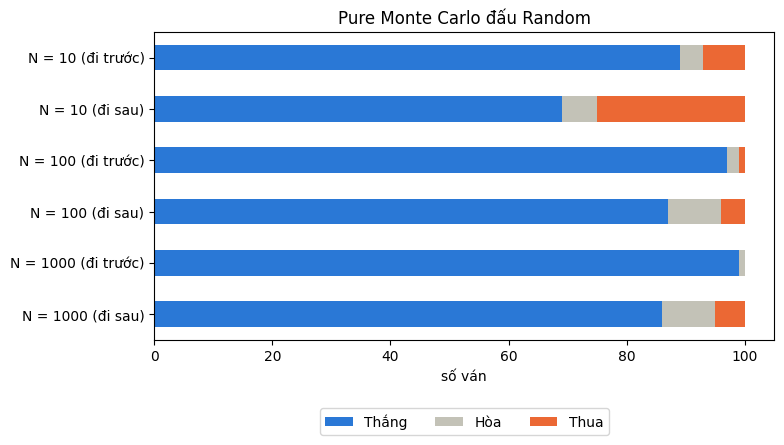

In [18]:
# pmcs đấu Random (N = 1000 mất vài phút)
DEBUG = 0
bang = pd.concat([danh_gia(lambda b, p: pmcs(b, N, p), f'N = {N}') for N in (10, 100, 1000)], ignore_index = True)
display(bang)
ve(bang, 'Pure Monte Carlo đấu Random')

**Nhận xét:** Chất lượng tăng theo N: N = 10 thua 32 ván (7 khi đi trước, 25 khi đi sau); N = 100 chỉ thua 5 ván; N = 1000 thua 5 ván và thắng 99 khi đi trước. Đổi lại thời gian tăng từ ≈ 3 ms lên ≈ 25 ms rồi ≈ 200 ms mỗi nước. Vì là thuật toán ngẫu nhiên nên pmcs vẫn có thể thua Random.